# 1. Importing the Dependencies

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans


# 2. Data Collection & Analysis

In [2]:
# loading the dataset
df = pd.read_csv('Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.shape

(200, 5)

In [4]:
# data information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [5]:
# checking for null values
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [6]:
# choosing the features for clustering
# We will use 'Annual Income (k$)' and 'Spending Score (1-100)' for clustering
# These features are numerical and suitable for KMeans clustering.
X = df.iloc[:, [3, 4]].values
print("Feature matrix shape:", X.shape)
print("First 5 samples:\n", X[:5])

Feature matrix shape: (200, 2)
First 5 samples:
 [[15 39]
 [15 81]
 [16  6]
 [16 77]
 [17 40]]


# 3. Choosing the number of clusters

In [7]:
# finding the optimal number of clusters using the Elbow method
# The Elbow method helps to determine the optimal number of clusters by plotting the within-cluster sum of squares (WCSS) against the number of clusters.
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', n_init=10, random_state=0)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

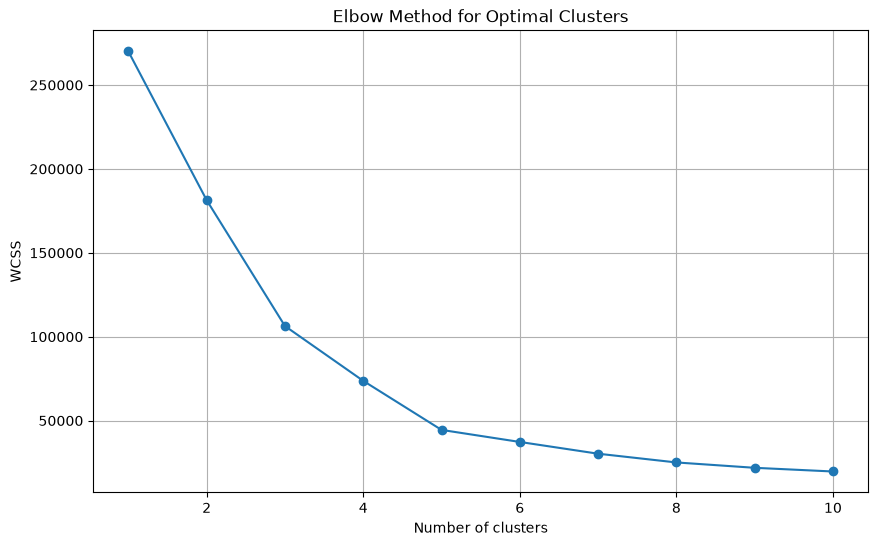

In [8]:
# plot the elbow method graph
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.grid()
plt.show()

### Optimum Number of clusters = 5

# 4. Training the k-Means Clustering Model

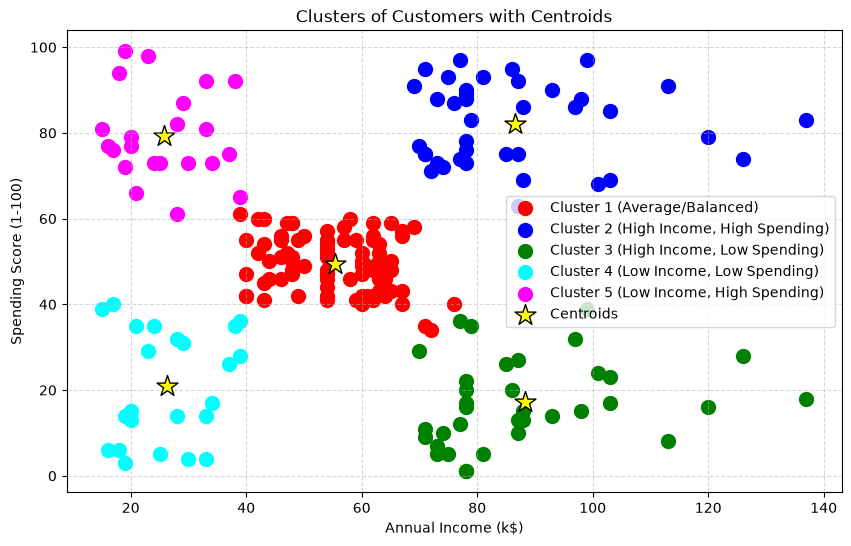

In [9]:
kmeans = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=0)
# returning the labels of the clusters
y_kmeans = kmeans.fit_predict(X)

# Visualizing the clusters with centroids
plt.figure(figsize=(10, 6))
plt.scatter(X[y_kmeans == 0, 0], X[y_kmeans == 0, 1], s=100, c='red', label='Cluster 1 (Average/Balanced)')
plt.scatter(X[y_kmeans == 1, 0], X[y_kmeans == 1, 1], s=100, c='blue', label='Cluster 2 (High Income, High Spending)')
plt.scatter(X[y_kmeans == 2, 0], X[y_kmeans == 2, 1], s=100, c='green', label='Cluster 3 (High Income, Low Spending)')
plt.scatter(X[y_kmeans == 3, 0], X[y_kmeans == 3, 1], s=100, c='cyan', label='Cluster 4 (Low Income, Low Spending)')
plt.scatter(X[y_kmeans == 4, 0], X[y_kmeans == 4, 1], s=100, c='magenta', label='Cluster 5 (Low Income, High Spending)')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=250, c='yellow', edgecolors='black', marker='*', label='Centroids')
plt.title('Clusters of Customers with Centroids')      
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 5. Customer Segmentation Report
### Based on Annual Income vs Spending Score

#### 🔴 Cluster 1 – Average Income, Average Spenders
* Color: Red

* Income: $40k – $70k

* Spending Score: 40 – 60

* Description: These are stable customers with average income and balanced spending. They are  loyal and consistent buyers.

* Business Tip: Good for long-term promotions, loyalty programs.

#### 🔵 Cluster 2 – High Income, High Spenders
* Color: Blue

* Income: $70k – $140k

* Spending Score: 70 – 100

* Description: These are premium customers who spend a lot and have high income.

* Business Tip: Focus on luxury or premium products, exclusive offers.

#### 🟢 Cluster 3 – High Income, Low Spenders
* Color: Green

* Income: $75k – $140k

* Spending Score: 0 – 40

* Description: These customers earn well but spend less.

* Business Tip: Target with discounts, personalized offers to increase spending.

#### 🔵 Cluster 4 – Low Income, Low Spenders
* Color: Cyan

* Income: $15k – $40k

* Spending Score: 0 – 40

* Description: Low earners and low spenders, price-sensitive group.

* Business Tip: Promote budget-friendly products or bundled offers.

#### 🟣 Cluster 5 – Low Income, High Spenders
* Color: Magenta

* Income: $15k – $40k

* Spending Score: 60 – 100

* Description: Surprising group – low income but high spenders. Possibly young or impulse buyers.

* Business Tip: Great for trendy or emotional marketing.

In [10]:
from sklearn.metrics import silhouette_score

# Model Evaluation Metrics
sil = silhouette_score(X, y_kmeans)
print(f"Silhouette Score (K=5): {sil:.4f}")
print(f"WCSS (Inertia): {kmeans.inertia_:.2f}")

# Adding cluster assignments to dataframe
df['Cluster'] = y_kmeans

# Cluster statistical summary table
cluster_summary = df.groupby('Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Avg_Age=('Age', 'mean'),
    Avg_Income_k=('Annual Income (k$)', 'mean'),
    Avg_Spending_Score=('Spending Score (1-100)', 'mean')
).reset_index()

cluster_summary['Percentage (%)'] = (cluster_summary['Customer_Count'] / len(df)) * 100
cluster_summary

Silhouette Score (K=5): 0.5539
WCSS (Inertia): 44448.46


,Cluster,Customer_Count,Avg_Age,Avg_Income_k,Avg_Spending_Score,Percentage (%)
0,0,81,42.716049,55.296296,49.518519,40.5
1,1,39,32.692308,86.538462,82.128205,19.5
2,2,35,41.114286,88.200000,17.114286,17.5
3,3,23,45.217391,26.304348,20.913043,11.5
4,4,22,25.272727,25.727273,79.363636,11.0
